# Лабораторная работа 6. Вариант 1
**Скрыпник Михаил Дмитриевич, МИК11.**

Бриф: афиша фестиваля робототехники. Единственный фактор: 1 → 4 шага. Seed: 101–105.

Фактическая среда: Windows, CPU float32, 4 потока. Это адаптация задания; Colab T4 и float16 не использовались.

Генерация выполнена скриптом `src/lab06_experiment.py`; исходный журнал сохранён в `reports/generation_log.txt`. Этот блокнот выполнен для повторного расчёта и проверки результатов. Ячейка с RUN_FULL_EXPERIMENT=True позволяет заново выполнить генерацию и оценку; это занимает длительное время и перезаписывает артефакты.

In [1]:
from pathlib import Path
import sys, json, hashlib
ROOT=Path.cwd()
assert (ROOT/'src/lab06_experiment.py').exists(), 'Откройте блокнот из LR06'
sys.path.insert(0,str(ROOT/'src'))
import lab06_lib as L
pre=json.loads((ROOT/'configs/preregistration.json').read_text(encoding='utf-8'))
print(json.dumps(pre,ensure_ascii=False,indent=2))
assert [k for k in pre['A'] if pre['A'][k]!=pre['B'][k]]==['steps']

C:\DONSTU\ai-in-creative-industries\LR05\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1027 16:21:37.574000 25616 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.


[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


{
  "recorded_at": "2026-10-27T15:50:31.463867+03:00",
  "variant": 1,
  "student": "Скрыпник Михаил Дмитриевич",
  "group": "МИК11",
  "factor": "num_inference_steps: 1 -> 4",
  "seeds": [
    101,
    102,
    103,
    104,
    105
  ],
  "prompt": "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
  "A": {
    "steps": 1,
    "guidance": 0.0,
    "size": 512
  },
  "B": {
    "steps": 4,
    "guidance": 0.0,
    "size": 512
  },
  "hypothesis": "Четыре шага повысят энергию границ и время; CLIP останется в пределах ±1,0. Контраст может возрасти.",
  "tolerance": {
    "clip": {
      "kind": "absolute",
      "value": 1.0
    },
    "edge": {
      "kind": "relative",
      "value": 0.1
    },
    "contrast": {
      "kind": "relative",
      "value": 0.1
    },
    "seconds": {
      "kind": "relative",
      "value": 0.2
    }
  },
  "direction": "CLIP, edge, contrast: р

## Код выполнения и сохранённый журнал
Гипотеза и допуски записаны до загрузки модели. Прогрев seed 0 не входит в измеряемую серию.

In [2]:
from lab06_experiment import generate_series, score_series
RUN_FULL_EXPERIMENT=False
if RUN_FULL_EXPERIMENT:
    generate_series()
    results=score_series()
else:
    results=json.loads((ROOT/'artifacts/results.json').read_text(encoding='utf-8'))
    print('Повторная генерация отключена; ниже исходный журнал фактического запуска:')
    log=(ROOT/'reports/generation_log.txt').read_text(encoding='utf-8',errors='replace')
    print('\n'.join(line for line in log.splitlines() if any(s in line for s in ['ДО запуска','Модель загружена','Прогрев','seed=','Проверка guidance','завершены'])))

Повторная генерация отключена; ниже исходный журнал фактического запуска:
Гипотеза и допуски записаны ДО запуска: 2026-10-27T15:50:31.463867+03:00
Модель загружена: 21.22 с; CPU, 4 потока, float32
Прогрев 1: 92.88 с
Прогрев 4: 94.33 с
A seed=101 steps=1 time=71.39s edge=0.041666 contrast=0.178326
B seed=101 steps=4 time=127.43s edge=0.090361 contrast=0.257167
A seed=102 steps=1 time=78.05s edge=0.041414 contrast=0.179453
B seed=102 steps=4 time=97.51s edge=0.081238 contrast=0.262184
A seed=103 steps=1 time=80.57s edge=0.054876 contrast=0.176351
B seed=103 steps=4 time=108.73s edge=0.121403 contrast=0.276400
A seed=104 steps=1 time=75.73s edge=0.047434 contrast=0.176234
B seed=104 steps=4 time=107.47s edge=0.100767 contrast=0.256147
A seed=105 steps=1 time=84.35s edge=0.044267 contrast=0.213237
B seed=105 steps=4 time=106.45s edge=0.076507 contrast=0.282588
Проверка guidance: {"guidance": 1.0, "cfg_active": false, "seconds": 75.25866640001186, "sha256": "5a97bb00a00adaf1920e051d99e46a2b

## Независимая проверка PNG и метрик
Сходство CLIP вновь вычисляется по сохранённым изображениям относительно неизменного английского брифа. Энергия границ: Собель с нормировкой 1/8 и отражением на границе; контраст: стандартное отклонение яркости.

In [3]:
import numpy as np, torch
from PIL import Image
from datetime import datetime
torch.set_num_threads(4)
clip=L.load_clip()
for row in results['measurements']:
    path=ROOT/row['path']
    assert hashlib.sha256(path.read_bytes()).hexdigest()==row['sha256']
    assert datetime.fromisoformat(pre['recorded_at'])<datetime.fromisoformat(row['started_at'])
    with Image.open(path) as im:
        assert im.size==(512,512) and im.mode=='RGB'
        assert np.isclose(L.edge_energy(im),row['edge'],rtol=0,atol=1e-12)
        assert np.isclose(L.contrast(im),row['contrast'],rtol=0,atol=1e-12)
        assert np.isclose(L.clip_sim(clip,im),row['clip'],rtol=0,atol=1e-5)
    print(row['mode'],row['seed'],'CLIP=',round(row['clip'],4),'edge=',round(row['edge'],6),'contrast=',round(row['contrast'],6),'time=',round(row['seconds'],2))
print('PASS: все 10 PNG, SHA-256, CLIP, Собель, контраст и время записи гипотезы проверены')

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 17756.41it/s]


[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


A 101 CLIP= 27.3593 edge= 0.041666 contrast= 0.178326 time= 71.39
B 101 CLIP= 30.3497 edge= 0.090361 contrast= 0.257167 time= 127.43


A 102 CLIP= 29.2678 edge= 0.041414 contrast= 0.179453 time= 78.05


B 102 CLIP= 29.6096 edge= 0.081238 contrast= 0.262184 time= 97.51
A 103 CLIP= 32.2888 edge= 0.054876 contrast= 0.176351 time= 80.57


B 103 CLIP= 29.7095 edge= 0.121403 contrast= 0.2764 time= 108.73
A 104 CLIP= 32.3623 edge= 0.047434 contrast= 0.176234 time= 75.73


B 104 CLIP= 27.2742 edge= 0.100767 contrast= 0.256147 time= 107.47
A 105 CLIP= 28.1354 edge= 0.044267 contrast= 0.213237 time= 84.35


B 105 CLIP= 27.1487 edge= 0.076507 contrast= 0.282588 time= 106.45
PASS: все 10 PNG, SHA-256, CLIP, Собель, контраст и время записи гипотезы проверены


## Средние, выборочное s, Δ и |Δ|/s
Критерий 2s является учебной эвристикой разброса по seed, а не тестом с заданным p-уровнем.

In [4]:
rows=L.summarize(results['measurements'],pre)
assert rows==results['summary']
for r in rows:
    print(f"{r['metric']:9s} A={r['A']:.6f} s={r['s']:.6f} B={r['B']:.6f} delta={r['delta']:+.6f} ratio={r['ratio']:.3f} 2s={r['criterion_2s']} допуск={r['classification']}")
print('Критерий 2s и практический допуск расходятся для:',[r['metric'] for r in rows if r['criterion_2s']!=r['outside_tolerance']])

clip      A=29.882732 s=2.331127 B=28.818326 delta=-1.064406 ratio=0.457 2s=False допуск=ухудшение
edge      A=0.045931 s=0.005560 B=0.094055 delta=+0.048124 ratio=8.656 2s=True допуск=улучшение
contrast  A=0.184720 s=0.015999 B=0.266897 delta=+0.082177 ratio=5.136 2s=True допуск=улучшение
seconds   A=78.016887 s=4.892537 B=109.518316 delta=+31.501429 ratio=6.439 2s=True допуск=ухудшение
Критерий 2s и практический допуск расходятся для: ['clip']


## Сравнительный лист, seed 101
Слева A, 1 шаг; справа B, 4 шага. Для всех пяти пар изображения сохранены без уменьшения в artifacts.

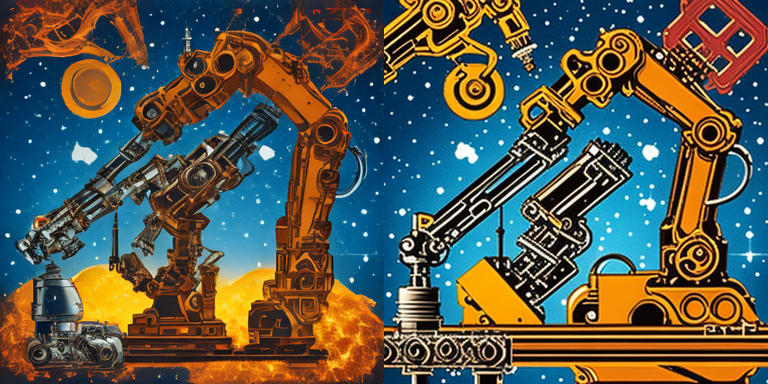

seed 101 A | B


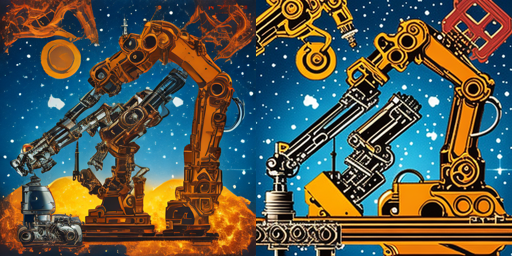

seed 102 A | B


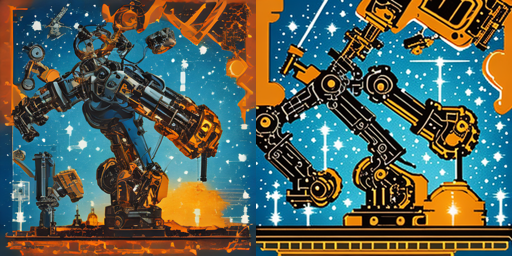

seed 103 A | B


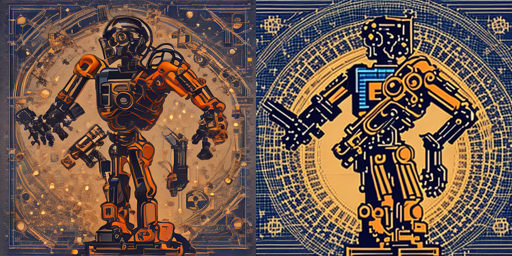

seed 104 A | B


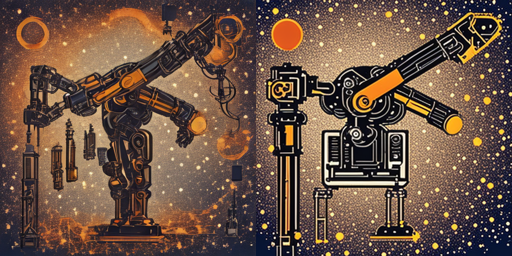

seed 105 A | B


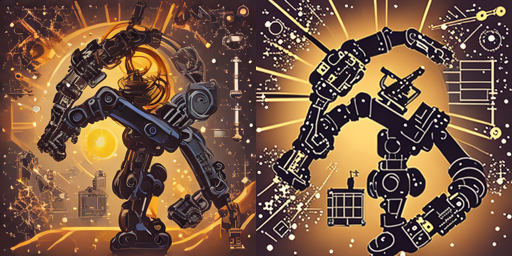

In [5]:
from IPython.display import display
display(Image.open(ROOT/'artifacts/comparison.png'))
for seed in L.SEEDS:
    pair=Image.new('RGB',(512,256))
    for i,mode in enumerate(['A','B']):
        with Image.open(ROOT/f'artifacts/{mode}_{seed}/result.png') as im:
            pair.paste(im.resize((256,256)),(256*i,0))
    print('seed',seed,'A | B')
    display(pair)

## Ошибка: ожидание CFG при guidance_scale=1.0
Проверяем сохранённые изображения: 0 и 1 дают одинаковые PNG; значение 3 используется как диагностика за пределами рекомендованного режима.

In [6]:
base=ROOT/'artifacts/A_101/result.png'
for key, r in results['guidance_check'].items():
    raw=(ROOT/r['path']).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==r['sha256']
    assert (raw==base.read_bytes())==r['same_sha256']
    print(key,json.dumps(r,ensure_ascii=False))
assert results['guidance_check']['1.0']['same_sha256']
assert results['guidance_check']['1.0']['cfg_active'] is False
assert results['guidance_check']['3.0']['cfg_active'] is True
print('PASS: диагностическая проверка guidance')

1.0 {"guidance": 1.0, "cfg_active": false, "seconds": 75.25866640001186, "sha256": "5a97bb00a00adaf1920e051d99e46a2bb366c811466814d96d17c5448109a7eb", "same_sha256": true, "pixel_equal": true, "mse": 0.0, "psnr_db": "Infinity", "path": "artifacts/guidance_1.png"}
3.0 {"guidance": 3.0, "cfg_active": true, "seconds": 95.97257339998032, "sha256": "5c408a41b1f274e02a654d46be0d9a84efc9288304324489367ae452232aa26b", "same_sha256": false, "pixel_equal": false, "mse": 3828.4329935709634, "psnr_db": 12.300593105289925, "path": "artifacts/guidance_3.png"}
PASS: диагностическая проверка guidance


## Допуск и вывод
Рост энергии границ и контраста классифицируется как рост соответствующего показателя; это не доказательство улучшения изображения. Окупаемость оценивается по правилу, записанному до запуска.

In [7]:
for metric,factors in [('clip',[0.5,1,2]),('edge',[0.5,1,2]),('contrast',[0.5,1,2]),('seconds',[0.5,1,2])]:
    r=next(r for r in rows if r['metric']==metric)
    print(metric, {f:abs(r['delta'])>r['threshold']*f for f in factors})
print('Визуальная оценка:')
print((ROOT/'artifacts/visual_review.json').read_text(encoding='utf-8'))
print('Полный вывод и ответы для защиты находятся в PDF-отчёте.')

clip {0.5: True, 1: True, 2: False}
edge {0.5: True, 1: True, 2: True}
contrast {0.5: True, 1: True, 2: True}
seconds {0.5: True, 1: True, 2: True}
Визуальная оценка:
{
  "method": "Визуальный просмотр каждого сохранённого PNG; субъективная оценка, без слепого экспертного теста.",
  "seed_101": "В A виден крупный сочленённый манипулятор и дополнительные механические элементы на синем фоне с янтарно-оранжевыми участками. В B общая диагональная композиция сохраняется, контуры становятся толще и темнее, жёлто-чёрные области выразительнее, часть тоновых переходов превращается в плоские пятна. Главный манипулятор узнаваем в обоих режимах. Фон со светлыми точками и дополнительные детали остаются насыщенными: требование чистой композиции выполнено лишь частично.",
  "pairs": [
    {
      "seed": 101,
      "recognizable_A": true,
      "recognizable_B": true,
      "dominant_A": true,
      "dominant_B": true,
      "observation": "В обоих режимах крупная сочленённая механическая рука занима

## Источники и лицензии
[SD-Turbo, закреплённая ревизия](https://huggingface.co/stabilityai/sd-turbo/tree/b261bac6fd2cf515557d5d0707481eafa0485ec2), [CLIP, закреплённая ревизия](https://huggingface.co/openai/clip-vit-base-patch32/tree/3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268). Методичка, карточки и лицензии сохранены в assignment. Использование учебное некоммерческое. Powered by Stability AI.